# Home assigment 2

Please give your name below:

In [1]:
name='Lê Huỳnh Thiện Nhân'

## Exercise 2

Now you will put together the pieces you learnt in previous labs in order to write a continuous energy Monte Carlo particle transport simulation of a Uranium sphere! Your goal is to estimate the k-effective and to try to find the critical radius of a U-235 sphere. 

Your assumptions:

- The geometry is a sphere
- The sphere is made of pure U-235.
- You only care about the following reactions: capture, fission and elastic scattering 
- All scattering is isotropic in the CM frame.
- Neutrons emerge isotropically from fission.
- Download the pointwise cross sections and the energy dependent nubar data (hint: you can use https://www-nds.iaea.org/).
- You can neglect that in a fission event the number of generated neutrons is stochastic, and assume that always nubar neutrons are created.
- For the prompt neutron energies you can sample the Watt-distribution (see lecture notes, or Datalab 4)
- You do not need to track time (thus all neutrons can be considered to be prompt)
- Initially launch neutrons from the center of the sphere, then store fission sites, and later sample the new fission sites from this "bank".

Your tasks:

1. Plot the data you downloaded: the cross section data and the nubar data.
2. Complete the function `run()` in order to estimate the k-eigenvalue of a sphere with a continous energy 3D Monte Carlo particle transport simulation. You are encouraged to separate parts into other functions as you saw in Datalab 5b (for example the direction transformations, Watt-spectrum sampling etc). You can include other input parameters and set default values if you feel needed. For each neutron generation estimate the k-eigenvalue based on the initial number of neutrons and the new neutrons after the generation.
3. Modify the return list in order to return and plot other data
    - Plot the k-eigenvalue estimate vs the generation number
    - Plot how the estimated mean k-eigenvalue converges. (use such figures to argue about reasonable values for `NGEN`, `NPG`, `NSKIP`). 
4. Investigate how the k-eigenvalue depends on the radius of the sphere. Visualize this with matplotlib.
5. Find the critical radius. You can do this either with manual trial and error, or use an optimization method.


Hints: in this exercise you have to merge your knowledge from datalab 5a (ie. batchwise estimation of k-effective) and from datalab 5b (ie. tracking neutrons). If you are not sure about the validity of your results you can compare your findings with the values of critical radii from [Wikipedia](https://en.wikipedia.org/wiki/Critical_mass). Try to have similar order of magnitude results.

To be fair, in a real MC criticality calculation, the initial number of neutrons per cycle also fluctuates, and the k-eigenvalue is calculated with some power iteration. In that case some care needs to be taken to renormalize the number of events to be placed in the bank, in order to have more or less the same amount of starting neutrons in each batch, otherwise sub and supercritical systems would be problematic to be simulated (here p200-225 gives some details on that: https://mcnp.lanl.gov/pdf_files/la-ur-16-29043.pdf). You don't need to worry about these. We are satisfied with a simpler approach. Rather you will initiate the same amount of neutrons in each cycle, regardless how many were produced before, and we place every fission site into the bank, and sample the locations from that. We also do not require an initial guess for the k-eigenvalue (as you can see in the link for the power iteration based method, an initial guess is needed). 

In the first few cycles when we launch neutrons only from the center, we will probably underestimate leakage, so the estimates of $k$ will be biased. Therefore NSKIP just means that the first NSKIP number of cycle estimates of the k-effective should not be taken into account when calculating the mean of the k-effective, since the spatial distribution of the fission source is still biased by our original source location, and not spread yet throughout the geometry. Actually for this simple geometry NSKIP plays a less important role, so if you are not certain about what it is, feel free to ignore it. 

In [22]:
import openmc
openmc.config['cross_sections'] = '/home/dell/endfb-vii.1-hdf5/cross_sections.xml'
import numpy as np
import scipy
import matplotlib.pyplot as plt
import os
import re

In [3]:
RHO = 18.95            # g/cm3 (density of U metal; use 18.71 for HEU if you prefer)
M_U = 235.0439         # g/mol
NA = 0.602214076       # Avogadro * 1e-24  -> N comes out in atoms/(barn cm)
N_DENS = RHO * NA / M_U
A = 233.025           
alpha = ((A-1)/(A+1))**2

def sig_extract(file):
    data = []
    with open(file, 'r') as content:
        for lines in content:
            line = lines.split()
            if len(line) == 3 and line[2] == "Lin-Lin":
                data.append([float(line[0]),float(line[1])])
    return np.array(data)
    
def nubar_extract(file):
    data = []
    with open(file, 'r') as content:
        for lines in content:
            line = lines.split()
            if len(line) == 6 and line[0] != '96':
                try:
                    data.append([float(insert_e(line[0])),float(insert_e(line[1]))])
                    data.append([float(insert_e(line[2])),float(insert_e(line[3]))])
                    data.append([float(insert_e(line[4])),float(insert_e(line[5]))])
                except ValueError:
                    continue
    return np.array(data)

def insert_e(val): # the data in the nubar file is in e form, but there's no e so I gotta insert an e into the data to turn them to float
    index = max(val.rfind('+'), val.rfind('-'))
    if 'e' not in val: 
        return val[:index]+'e'+val[index:]
    else: 
        return val

def watt(E): # from old datalabs
    C1 = 0.453
    C2 = 0.965
    C3 = 2.29
    return C1*np.exp(-E/C2)*np.sinh(np.sqrt(C3*E))

E_grid = np.linspace(0, 20, 20001)          # MeV; the pdf beyond 20 MeV is negligible
pdf = watt(E_grid)
cdf = np.concatenate(([0.0], np.cumsum(0.5*(pdf[1:] + pdf[:-1]) * np.diff(E_grid)))) 
cdf /= cdf[-1]                               # normalization

def sample_watt(n, rng):
    return np.interp(rng.random(n), cdf, E_grid)

def iso_sample(n, rng):
    mu = rng.uniform(-1,1,n)
    phi = rng.uniform(0,2*np.pi,n)
    sin = np.sqrt(1-mu**2)
    x = sin*np.cos(phi)
    y = sin*np.sin(phi)
    z = mu
    return np.column_stack((x,y,z))

def rotate(u, mu, phi):
    ux, uy, uz = u.T
    s = np.sqrt(1 - mu**2)
    d = np.sqrt(1 - uz**2)
    cp, sp = np.cos(phi), np.sin(phi)

    pole = d < 1e-8                    # to avoid dividing by zero when the direction vector u is almost along the z-axis
    d = np.where(pole, 1.0, d)

    nx = np.where(pole, s*cp,  mu*ux + s*(ux*uz*cp - uy*sp)/d)
    ny = np.where(pole, s*sp, mu*uy + s*(uy*uz*cp + ux*sp)/d)
    nz = np.where(pole, np.sign(uz)*mu, mu*uz - s*cp*d)
    return np.column_stack((nx, ny, nz))

def scattering(E,u,rng):
    n = len(E)
    muC = rng.uniform(-1,1,n)
    phi = rng.uniform(0, 2*np.pi,n)
    E_new = 1/2 * E * (1+alpha + (1-alpha)*muC)
    muL = (1+A*muC)/np.sqrt(1+A**2+2*A*muC)
    u_new = rotate(u, muL, phi)
    return E_new, u_new

def track_generation(src_pos, R, rng): 
    n = len(src_pos)
    pos = src_pos.copy()
    E = sample_watt(n, rng) * 1e6 # from MeV to eV
    u = iso_sample(n, rng)
    bank = []

    while len(E) > 0:
        sig_el  = np.interp(E, elastic_e, elastic_sig)
        sig_cap = np.interp(E, capture_e, capture_sig)
        sig_fis = np.interp(E, fission_e, fission_sig)
        sig_tot = sig_el + sig_cap + sig_fis

        # flight
        d = -np.log(rng.random(len(E))) / (N_DENS * sig_tot) # Datalab4
        pos = pos + d[:, None] * u

        # leakage: drop neutrons outside the sphere
        inside = (pos**2).sum(axis=1) <= R**2
        pos, u, E = pos[inside], u[inside], E[inside]
        sig_el, sig_cap, sig_fis, sig_tot = sig_el[inside], sig_cap[inside], sig_fis[inside], sig_tot[inside]

        # choose reaction
        xi = rng.random(len(E)) * sig_tot # the probability of reaction i happening is sig_i/sig_tot
        scat = xi < sig_el # so we generate a random number and if it's less than that ratio then it's elastic scattering
        cap  = ~scat & (xi < sig_el + sig_cap) # if it's NOT(scat) AND (the random number is less than that ratio plus another ratio)
        fis  = ~(scat | cap) # if it's NOT(scat OR cap) then it's fis

        # fission: add ~nubar sites to the bank (neutron then dies)
        if fis.any(): # IF the array fis had AT LEAST a single True
            nu = np.interp(E[fis], nu_e, nu_nubar)
            n_new = np.floor(nu + rng.random(len(nu))).astype(int) # stochastic rounding, doing floor(nu) would create bias by shifting everything down
            bank.append(np.repeat(pos[fis], n_new, axis=0)) # repeats row i n_new[i] times, so if neutron 1 at x1,y1,z1 and neutron 2 at x2,y2,z2 created 2, 3 neutrons, those 2 would be at x1,y1,z1, and the other 3 would be at x2,y2,z2
        # explaining stochastic rounding: if we have 1.4 then round it to 1 40% of the time and 2 60% of the time so the mean would still be 1.4

        # scatter: survivors continue
        E_s, u_s = scattering(E[scat], u[scat], rng)
        pos, E, u = pos[scat], E_s, u_s
    return np.concatenate(bank) if bank else np.empty((0, 3))
# so this essentially loops through every neutron in a generation, so it either fission, gets captured, leaked. 
# if it's fission then write a coordinates of the product neutrons and how many there are
# and we continue considering the neutrons that WEREN'T fissioned, captured, or leaked to elastic scatter until they ALL get fissioned, captured, or leaked. 
# we can do this because we're just examining neutron generations, even if the neutrons that were fissioned and created nubar neutrons
# while there were still other neutrons of the same generation who elastic scattered, the time delay doesn't matter because it's still generation 0 so it's not of our interest

def run(R, NGEN, NPG, NSKIP, seed = None, return_all = False):
    """Function to perform a criticality calculation in a U-235 sphere.
    
    Parameters
    ----------
    R : float
        Radius of the sphere
    NGEN : int
        Number of neutron generations
    NPG : int
        Number of neutrons per generation
    NSKIP : int
        Number of inactive generations which will not be taken into account for estimating the k-eigenvalue
    
    Returns
    -------
    keff : float
        The estimated mean k-eigenvalue of the system
    kstd : float
        The standard deviation of the estimated k-eigenvalue
    """
    rng = np.random.default_rng(seed)
    src = np.zeros((NPG,3))
    ks = np.zeros(NGEN)
    for i in range(NGEN):
        bank = track_generation(src, R, rng)
        ks[i] = len(bank)/NPG
        if len(bank)>0:
            src = bank[rng.integers(len(bank), size = NPG)] # after NSKIP generation, the distribution of neutrons reaches an equilibrium state, which means the pos of neutrons can be whatever, as long as it follows that distribution
            # TLDR; the distribution of neutrons "bão hòa" after a long time (hence NSKIP)
        else: src = np.zeros((NPG,3))
    active_gen = ks[NSKIP:]
    keff = active_gen.mean()
    kstd = active_gen.std()
    return (keff, kstd, ks) if return_all else (keff, kstd)

capture = sig_extract('U235_capture.txt')
elastic = sig_extract('U235_elastic.txt')
fission = sig_extract('U235_fission.txt')
capture_e = capture[:,0]
capture_sig = capture[:,1]
elastic_e = elastic[:,0]
elastic_sig = elastic[:,1]
fission_e = fission[:,0]
fission_sig = fission[:,1]

nu = nubar_extract('U235_nubar.txt')
nu_e = nu[:,0]
nu_nubar = nu[:,1]

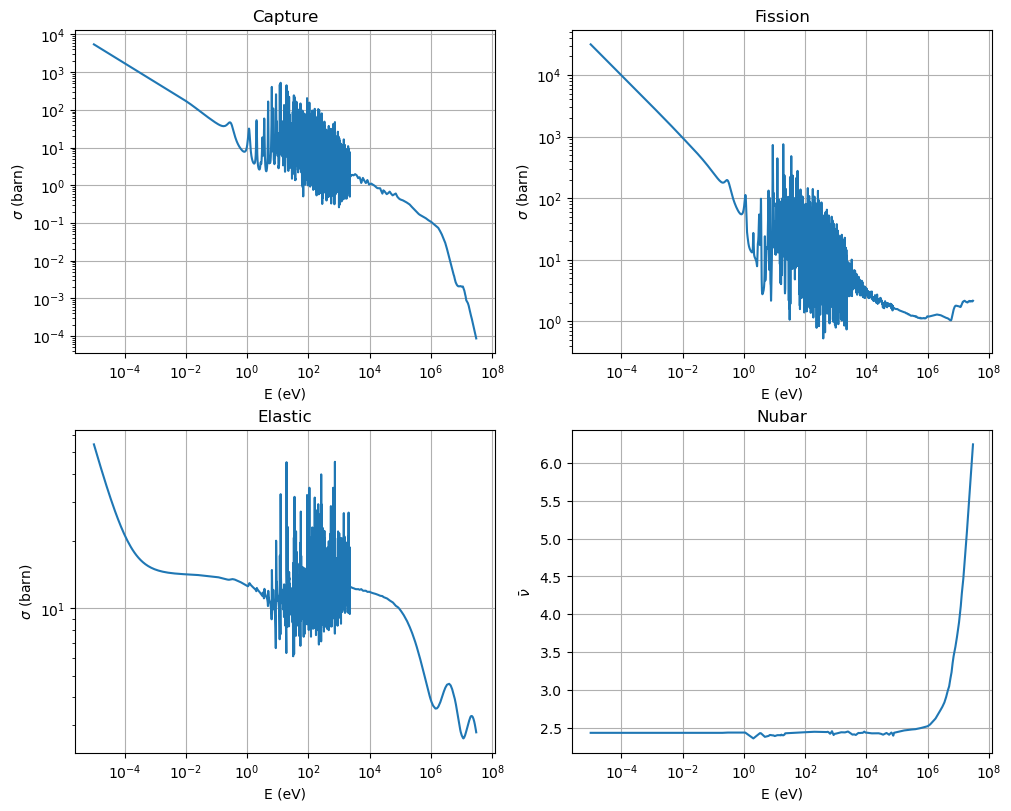

In [4]:
fig, ax = plt.subplots(2,2, figsize = (10,8), constrained_layout = True)
ax[0,0].loglog(capture_e,capture_sig)
ax[0,0].set(title = "Capture", xlabel = "E (eV)", ylabel = "$\\sigma$ (barn)")

ax[1,0].loglog(elastic_e,elastic_sig)
ax[1,0].set(title = "Elastic", xlabel = "E (eV)", ylabel = "$\\sigma$ (barn)")

ax[0,1].loglog(fission_e,fission_sig)
ax[0,1].set(title = "Fission", xlabel = "E (eV)", ylabel = "$\\sigma$ (barn)")

ax[1,1].semilogx(nu_e,nu_nubar)
ax[1,1].set(title = "Nubar", xlabel = "E (eV)", ylabel = "$\\bar\\nu$")

for a in ax.flat:
    a.grid(True)
plt.show()

In [5]:
rng = np.random.default_rng(1)
E = sample_watt(100000, rng)
print(E.mean())

1.9799934351905704


In [6]:
u = iso_sample(10000,rng)
ux, uy, uz = u.T
print(u)
print(ux**2 + uy**2 + uz**2)

[[ 0.59517859 -0.75807692 -0.26661175]
 [ 0.83293269 -0.38292041  0.39949353]
 [ 0.45172962 -0.87199175 -0.18860206]
 ...
 [ 0.13377208  0.52132753 -0.84280641]
 [ 0.04369171  0.99559565 -0.08294777]
 [ 0.7616688   0.32367218 -0.56133498]]
[1. 1. 1. ... 1. 1. 1.]


In [7]:
n = 1000000
E = np.ones(n)
muC = rng.uniform(-1,1,n)
phi = rng.uniform(0, 2*np.pi,n)
E_new = 1/2 * E * (1+alpha + (1-alpha)*muC)
muL = (1+A*muC)/np.sqrt(1+A**2+2*A*muC)
print(muL.mean())
print(2/(3*A))
print(E_new.min()/alpha, E_new.max())

0.0029662512711729834
0.002860923363015413
1.0000000626210686 0.9999999976969046


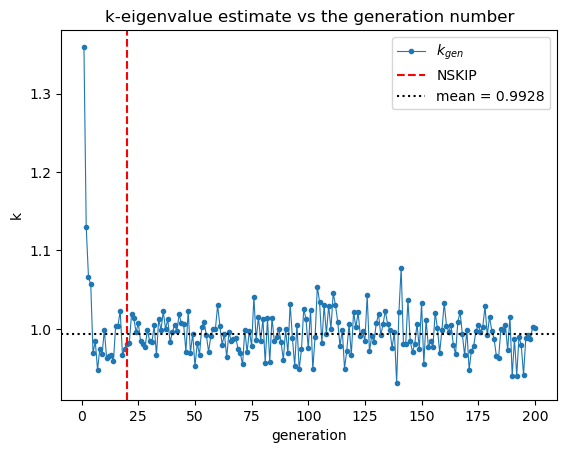

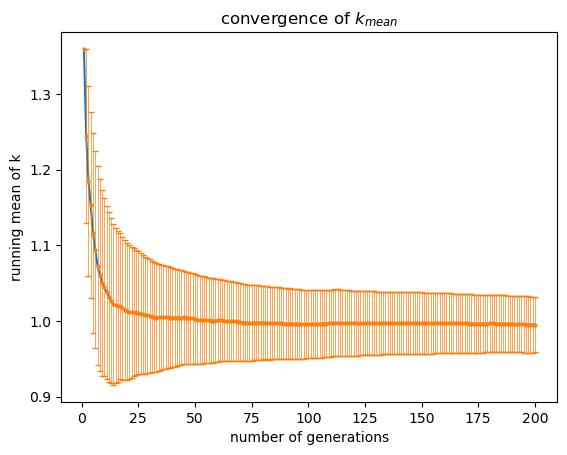

In [9]:
keff, kstd, ks = run(8.0, 200, 3000, 10, seed = 1, return_all = True)
gen = np.arange(1, len(ks)+1)

# Plot of k at the ith generation
plt.figure()
plt.plot(gen, ks, "o-", ms=3, lw=0.8, label="$k_{gen}$")
plt.axvline(20, color="r", ls="--", label="NSKIP")
plt.axhline(keff, color="k", ls=":", label=f"mean = {keff:.4f}")
plt.xlabel("generation")
plt.ylabel("k")
plt.title("k-eigenvalue estimate vs the generation number")
plt.legend()


# Plot of k-mean upto the ith generation
running_mean = np.cumsum(ks) / gen
running_err = np.array([ks[:g].std() if g > 1 else np.nan for g in gen])
plt.figure()
plt.plot(gen, running_mean)
plt.title("convergence of $k_{mean}$")
plt.xlabel("number of generations")
plt.ylabel("running mean of k")
plt.errorbar(gen, running_mean, yerr=running_err, fmt="o", ms=2, capsize=2, elinewidth=0.5)
plt.show()

We see that for NPG = 3000, 200 generation makes the error small enough so I picked NGEN = 200, and at around gen 5, the k starts to stabilize, so for safety's sake, we can pick NSKIP = 10

In [14]:
radii = np.linspace(5,25,20)
keff_r = np.zeros(len(radii))
kstd_r = np.zeros(len(radii))
for i, R in enumerate(radii):
    keff_r[i], kstd_r[i] = run(R,200,3000,10, seed = 1)

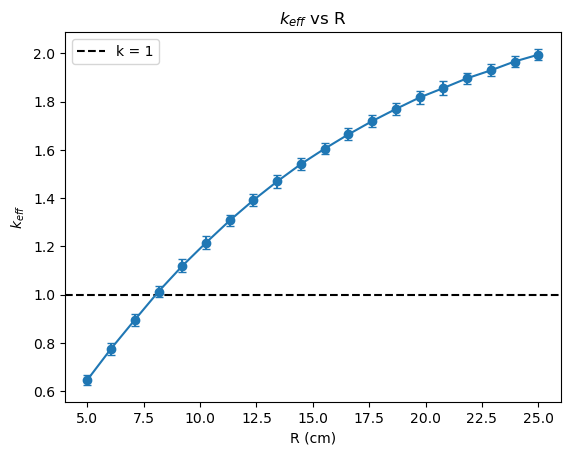

In [17]:
plt.errorbar(radii, keff_r, yerr=kstd_r, fmt="o-", capsize=3)
plt.axhline(1, color="k", ls="--", label="k = 1")
plt.title("$k_{eff}$ vs R")
plt.xlabel("R (cm)")
plt.ylabel("$k_{eff}$")
plt.legend()
plt.show()

Seeing the plot, we see that when k is 1, the critical radius $R_c \approx 8.0cm$, to get a better approximation, we can visualize the plot around $8.0cm$ and get a better approximation:

In [18]:
radii = np.linspace(7,9,20)
for i, R in enumerate(radii):
    keff_r[i], kstd_r[i] = run(R,200,3000,10, seed = 1)

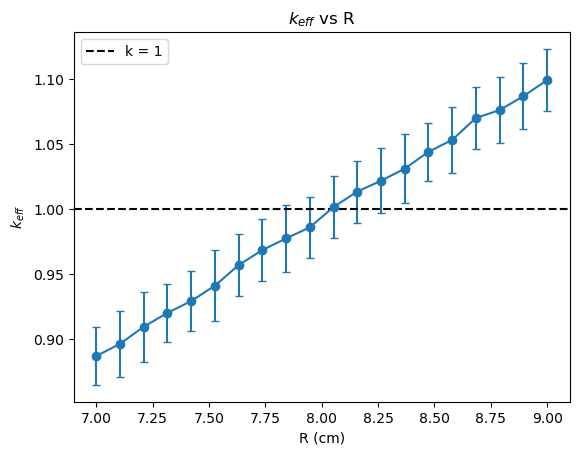

In [19]:
plt.errorbar(radii, keff_r, yerr=kstd_r, fmt="o-", capsize=3)
plt.axhline(1, color="k", ls="--", label="k = 1")
plt.title("$k_{eff}$ vs R")
plt.xlabel("R (cm)")
plt.ylabel("$k_{eff}$")
plt.legend()
plt.show()

In [20]:
radii = np.linspace(7.75,8.25,20)
for i, R in enumerate(radii):
    keff_r[i], kstd_r[i] = run(R,200,3000,10, seed = 1)

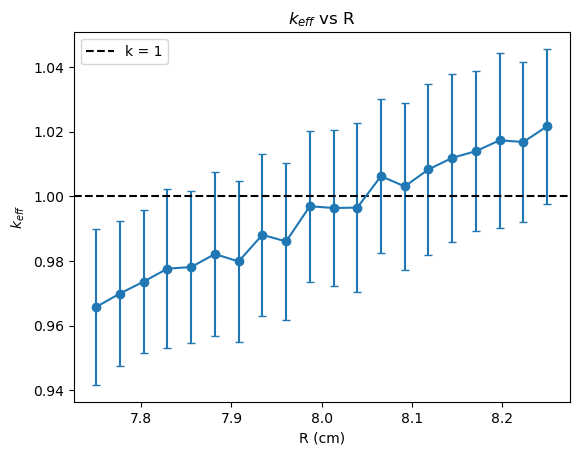

In [21]:
plt.errorbar(radii, keff_r, yerr=kstd_r, fmt="o-", capsize=3)
plt.axhline(1, color="k", ls="--", label="k = 1")
plt.title("$k_{eff}$ vs R")
plt.xlabel("R (cm)")
plt.ylabel("$k_{eff}$")
plt.legend()
plt.show()

The error is crazy, we can try to use scipy to optimize

In [29]:
model = lambda R: run(R,200,3000,10, seed = 1)[0]-1 # minus 1 is because we want k to be 1
root = scipy.optimize.brentq(model,7.5,8.5)

In [30]:
print(root)

8.055260664718716


So this agrees with the plot, the intersection when the system is at the critical is at around $R_c = 8.05cm$